In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.info()
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
   Sl_No  Customer Key  Avg_Credit_Limit  Total_Credit_Cards  \
0      1         87073            100000                   2   
1      2         38414             50000                   3   
2      3         17341             50000                   7   
3      4         40496             30000                   5   
4      5         47437            100000                   6   

   Total_visits_bank  Total_visits_online  Total_ca

In [3]:
X = df.iloc[:, 2:].values
print(df.columns[2:])

Index(['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
       'Total_visits_online', 'Total_calls_made'],
      dtype='str')


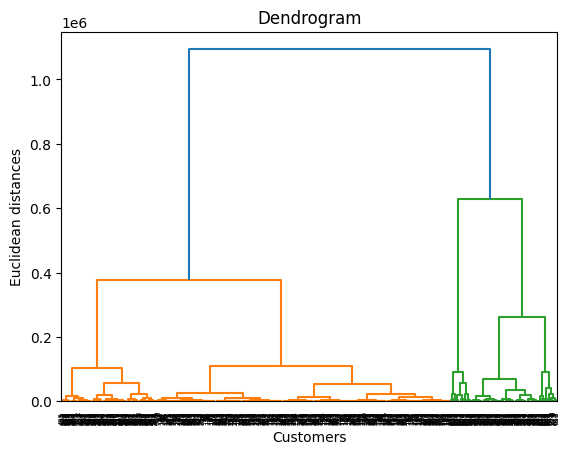

In [4]:
import scipy.cluster.hierarchy as sch

dendrogram = sch.dendrogram(sch.linkage(X, method = 'ward'))
plt.title('Dendrogram')
plt.xlabel('Customers')
plt.ylabel('Euclidean distances')
plt.show()

In [5]:
from sklearn.cluster import AgglomerativeClustering
hc = AgglomerativeClustering(n_clusters = 3, metric = 'euclidean', linkage = 'ward')
y_hc = hc.fit_predict(X)

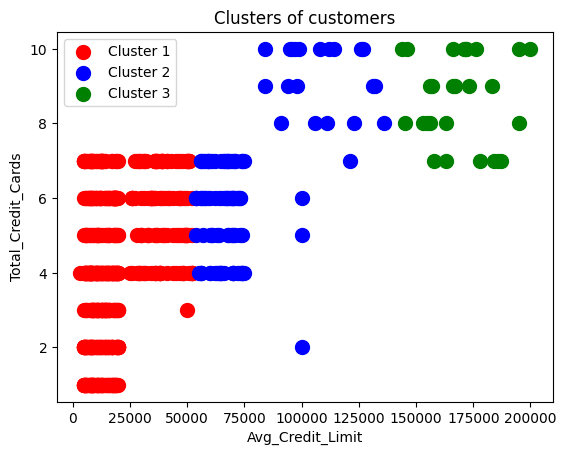

In [6]:
col_x = 'Avg_Credit_Limit'
col_y = 'Total_Credit_Cards'
X_plot = df[[col_x, col_y]].values

plt.scatter(X_plot[y_hc == 0, 0], X_plot[y_hc == 0, 1], s = 100, c = 'red', label = 'Cluster 1')
plt.scatter(X_plot[y_hc == 1, 0], X_plot[y_hc == 1, 1], s = 100, c = 'blue', label = 'Cluster 2')
plt.scatter(X_plot[y_hc == 2, 0], X_plot[y_hc == 2, 1], s = 100, c = 'green', label = 'Cluster 3')
plt.title('Clusters of customers')
plt.xlabel(col_x)
plt.ylabel(col_y)
plt.legend()
plt.show()

In [7]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

silhouette_avg = silhouette_score(X, y_hc)
dbi_score = davies_bouldin_score(X, y_hc)
print(f'Silhouette Coefficient: {silhouette_avg}')
print(f'Davies-Bouldin Index: {dbi_score}')

Silhouette Coefficient: 0.6811232268244817
Davies-Bouldin Index: 0.38800576073929305
